# **1. Perkenalan Dataset**


1. Sumber Dataset:

  Dataset ini diperoleh dari public repository yaitu kaggle. Dataset yang digunakan merupakan data transaksi penjualan produk dari sebuah retail modern selama satu tahun.

2. Ketentuan Dataset:

  - Tanpa Label:
Dataset ini tidak memiliki label atau kelas yang ditetapkan, sehingga cocok untuk penerapan teknik unsupervised learning seperti clustering.

  - Jumlah Baris:
Dataset terdiri dari 1.048.576 baris.

3. Tipe Data:

  - Numerikal:
  Contohnya terdapat fitur Unit_Price (harga produk), Quantity (jumlah pembelian), Discount (persentase diskon), dan Total_Price (total transaksi).

  - Kategorikal:
Contohnya terdapat fitur Customer_Type (misalnya B2B atau B2C), Product (nama produk), Category (jenis produk), dan Region (wilayah penjualan).

4. Deskripsi Data:
  
  Dataset ini mencakup berbagai informasi terkait transaksi, seperti:

  - Identifikasi Transaksi dan Pelanggan:

    Fitur seperti Order_ID dan Customer_ID memberikan identifikasi unik untuk setiap transaksi dan pelanggan.

  - Detail Transaksi:

    Informasi produk yang dibeli (Product dan Category), harga satuan, jumlah pembelian, dan diskon yang diberikan sehingga menghasilkan Total_Price.

  - Informasi Pelanggan dan Waktu Transaksi:

    Fitur Customer_Type, Region, dan Order_Date memungkinkan analisis segmentasi berdasarkan jenis pelanggan, lokasi, dan tren penjualan dari waktu ke waktu.

5. Manfaat Dataset untuk Analisis:

  - Clustering:

    Karena dataset ini tidak memiliki label, metode clustering dapat diterapkan untuk mengelompokkan transaksi atau pelanggan berdasarkan pola pembelian dan karakteristik lainnya.

  - Feature Engineering:

    Dengan kombinasi data numerikal dan kategorikal, dapat dilakukan pembuatan fitur baru untuk meningkatkan kualitas analisis.

  - Pengembangan Model Klasifikasi:
    Setelah proses clustering, label yang dihasilkan dapat digunakan sebagai target dalam membangun model klasifikasi guna memprediksi segmen pelanggan di masa mendatang.

  Dataset ini dirancang untuk mendukung analisis lanjutan dengan menyediakan data yang cukup kompleks dan bervariasi, sehingga memungkinkan eksplorasi mendalam baik dalam proses clustering maupun dalam tahap klasifikasi.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [45]:
# Import library untuk manipulasi data
import pandas as pd
import numpy as np

# Import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Import library untuk preprocessing data
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# Import library untuk clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

# Jika Anda menggunakan Google Colab dan dataset berada di Google Drive:
from google.colab import drive
drive.mount('/content/drive')



# Set style untuk visualisasi
sns.set(style="whitegrid")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

In [46]:
file_path = '/content/drive/MyDrive/dataset/submission_2/dataset.csv'

# Membaca dataset asli
df = pd.read_csv(file_path)

# Melakukan sampling sebanyak 20.000 baris secara acak
df_sample = df.sample(n=20000, random_state=42)

# Menampilkan 5 baris awal dataset untuk mengecek struktur data
print(df_sample.head())

# Informasi umum mengenai dataset (misalnya jumlah baris, kolom, dan tipe data)
print(df_sample.info())


           Order_ID Customer_ID Customer_Type         Product  \
4990465  ORD1663596     CUS5073           B2B  Hohes C Orange   
5995542  ORD1999010      CUS141           B2B      Fritz-Kola   
1044351   ORD347756      CUS562           B2B          Merlot   
1802181   ORD600360     CUS7718           B2B  Moët & Chandon   
6900691  ORD2300591     CUS6160           B2C   Granini Apple   

                    Category  Unit_Price  Quantity  Discount  Total_Price  \
4990465               Juices        1.87        74      0.10       124.54   
5995542          Soft Drinks        1.87        18      0.05        31.98   
1044351  Alcoholic Beverages       12.04        71      0.15       726.61   
1802181  Alcoholic Beverages       64.91        91      0.10      5316.13   
6900691               Juices        1.64         4      0.00         6.56   

                Region  Order_Date  
4990465  Niedersachsen  2023-11-29  
5995542         Bremen  2021-05-13  
1044351      Thüringen  2021-04-21 

# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset. EDA bertujuan untuk:

1. **Memahami Struktur Data**
   - Tinjau jumlah baris dan kolom dalam dataset.  
   - Tinjau jenis data di setiap kolom (numerikal atau kategorikal).

2. **Menangani Data yang Hilang**  
   - Identifikasi dan analisis data yang hilang (*missing values*). Tentukan langkah-langkah yang diperlukan untuk menangani data yang hilang, seperti pengisian atau penghapusan data tersebut.

3. **Analisis Distribusi dan Korelasi**  
   - Analisis distribusi variabel numerik dengan statistik deskriptif dan visualisasi seperti histogram atau boxplot.  
   - Periksa hubungan antara variabel menggunakan matriks korelasi atau scatter plot.

4. **Visualisasi Data**  
   - Buat visualisasi dasar seperti grafik distribusi dan diagram batang untuk variabel kategorikal.  
   - Gunakan heatmap atau pairplot untuk menganalisis korelasi antar variabel.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [47]:
# Menampilkan 5 baris awal data
print("Lima baris pertama dataset:")
print(df_sample.head())

# Menampilkan informasi umum mengenai dataset: jumlah baris, kolom, dan tipe data setiap kolom
print("\nInformasi Dataset:")
print(df_sample.info())

# Menampilkan tipe data masing-masing kolom secara eksplisit
print("\nTipe Data Setiap Kolom:")
print(df_sample.dtypes)

# Menampilkan ringkasan statistik untuk kolom numerikal (opsional)
print("\nRingkasan Statistik Data Numerikal:")
print(df_sample.describe())


Lima baris pertama dataset:
           Order_ID Customer_ID Customer_Type         Product  \
4990465  ORD1663596     CUS5073           B2B  Hohes C Orange   
5995542  ORD1999010      CUS141           B2B      Fritz-Kola   
1044351   ORD347756      CUS562           B2B          Merlot   
1802181   ORD600360     CUS7718           B2B  Moët & Chandon   
6900691  ORD2300591     CUS6160           B2C   Granini Apple   

                    Category  Unit_Price  Quantity  Discount  Total_Price  \
4990465               Juices        1.87        74      0.10       124.54   
5995542          Soft Drinks        1.87        18      0.05        31.98   
1044351  Alcoholic Beverages       12.04        71      0.15       726.61   
1802181  Alcoholic Beverages       64.91        91      0.10      5316.13   
6900691               Juices        1.64         4      0.00         6.56   

                Region  Order_Date  
4990465  Niedersachsen  2023-11-29  
5995542         Bremen  2021-05-13  
1044351

In [48]:
# Menampilkan tipe data dari setiap kolom
print("Tipe Data Setiap Kolom:")
print(df_sample.dtypes)

# Memilih kolom numerikal
numeric_columns = df_sample.select_dtypes(include=['int64', 'float64']).columns
print("\nKolom Numerikal:")
print(numeric_columns)

# Memilih kolom kategorikal (biasanya bertipe object atau category)
categorical_columns = df_sample.select_dtypes(include=['object', 'category']).columns
print("\nKolom Kategorikal:")
print(categorical_columns)


Tipe Data Setiap Kolom:
Order_ID          object
Customer_ID       object
Customer_Type     object
Product           object
Category          object
Unit_Price       float64
Quantity           int64
Discount         float64
Total_Price      float64
Region            object
Order_Date        object
dtype: object

Kolom Numerikal:
Index(['Unit_Price', 'Quantity', 'Discount', 'Total_Price'], dtype='object')

Kolom Kategorikal:
Index(['Order_ID', 'Customer_ID', 'Customer_Type', 'Product', 'Category',
       'Region', 'Order_Date'],
      dtype='object')


In [49]:
# Mengecek jumlah missing values per kolom
print(df_sample.isnull().sum())

# Jika terdapat missing values, Anda bisa mengisi dengan median/mean untuk numerikal, atau modus untuk kategorikal
# Contoh: Mengisi missing values pada kolom 'Unit_Price' dengan median
# df_sample['Unit_Price'].fillna(df_sample['Unit_Price'].median(), inplace=True)

# Atau menghapus baris yang memiliki missing values
# df_sample.dropna(inplace=True)


Order_ID         0
Customer_ID      0
Customer_Type    0
Product          0
Category         0
Unit_Price       0
Quantity         0
Discount         0
Total_Price      0
Region           0
Order_Date       0
dtype: int64


In [50]:
# --- 2. Feature Engineering ---
# a. Konversi Order_Date ke tipe datetime dan ekstrak bulan sebagai fitur kategorikal baru
df_sample['Order_Date'] = pd.to_datetime(df_sample['Order_Date'])
df_sample['Order_Month'] = df_sample['Order_Date'].dt.month  # fitur numerik (bulan)

# b. Buat fitur baru: Revenue_per_Unit = Total_Price / Quantity
df_sample['Revenue_per_Unit'] = df_sample['Total_Price'] / df_sample['Quantity']

# c. Pilih fitur yang akan digunakan untuk clustering
# Misalnya, kita gunakan:
#   - Unit_Price (numerikal)
#   - Quantity (numerikal)
#   - Total_Price (numerikal)
#   - Revenue_per_Unit (numerikal)
#   - Customer_Type (kategorikal)
features = ['Unit_Price', 'Quantity', 'Total_Price', 'Revenue_per_Unit', 'Customer_Type']

numeric_features = ['Unit_Price', 'Quantity', 'Total_Price', 'Revenue_per_Unit' ]
categorical_features = ['Customer_Type']


In [51]:
print("\nRingkasan Statistik untuk 5 Fitur:")
print(df_sample[features].describe())


Ringkasan Statistik untuk 5 Fitur:
         Unit_Price      Quantity   Total_Price  Revenue_per_Unit
count  20000.000000  20000.000000  20000.000000      20000.000000
mean       5.868649     22.849650    133.954798          5.688894
std       14.970786     26.649206    526.936049         14.571226
min        0.330000      1.000000      0.350000          0.296667
25%        1.050000      6.000000      8.400000          1.028472
50%        1.750000     11.000000     20.760000          1.710000
75%        3.170000     29.000000     67.720000          3.120000
max      138.720000    100.000000  10111.960000        124.848049


In [52]:
# --- 3. Menangani Missing Values ---
# Cek missing values untuk 5 fitur
print("\nJumlah Missing Values untuk 5 Fitur:")
print(df_sample[features].isnull().sum())


Jumlah Missing Values untuk 5 Fitur:
Unit_Price          0
Quantity            0
Total_Price         0
Revenue_per_Unit    0
Customer_Type       0
dtype: int64



Statistik Deskriptif Kolom Kategorikal:
       Customer_Type         Product Category   Region
count          20000           20000    20000    20000
unique             2              47        4       16
top              B2C  Hohes C Orange   Juices  Hamburg
freq           12979             783     5065     1367


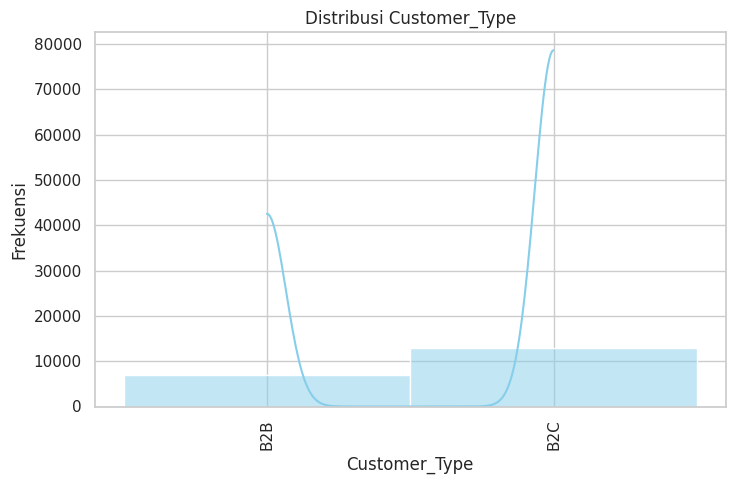

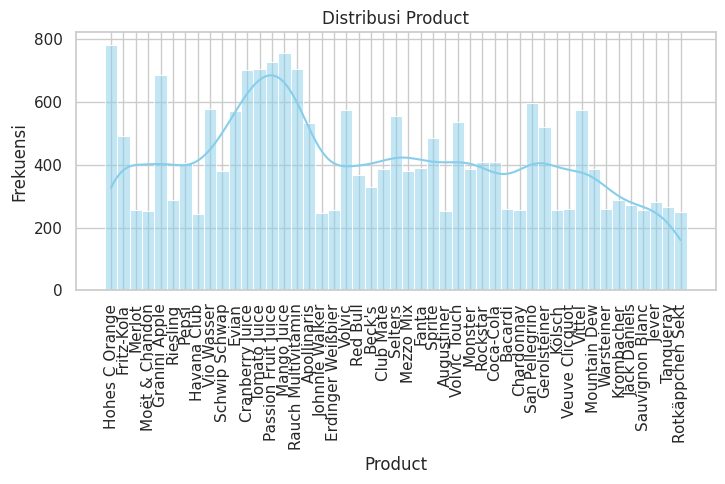

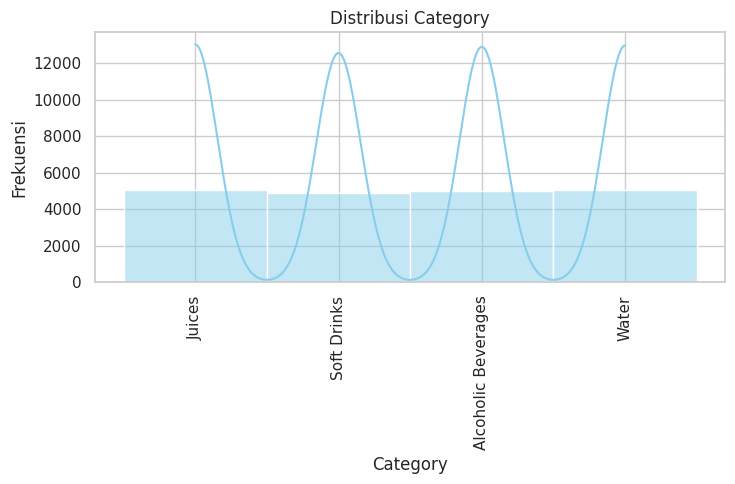

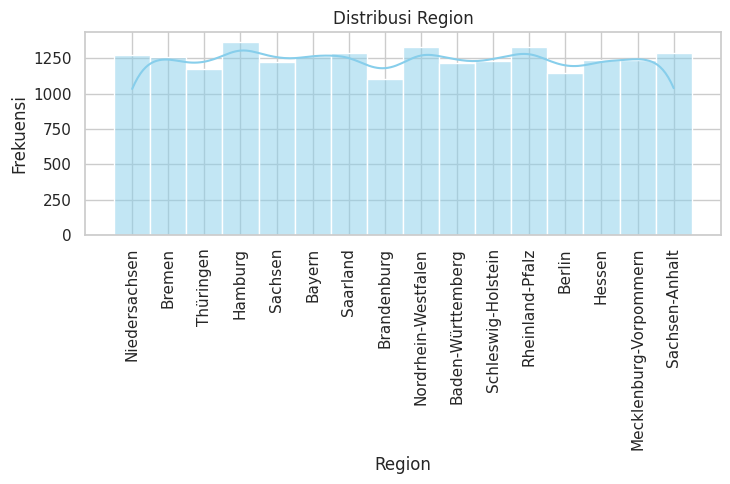

In [53]:
# Hapus kolom Order_ID dan Customer_ID untuk analisis distribusi
df_dist = df_sample.drop(columns=['Order_ID', 'Customer_ID'])

# Pilih kolom kategorikal dari df_dist
categorical_columns = df_dist.select_dtypes(include=['object', 'category']).columns

print("\nStatistik Deskriptif Kolom Kategorikal:")
print(df_dist[categorical_columns].describe())

# Visualisasi histogram dan boxplot untuk setiap kolom kategorikal
for col in categorical_columns:
    plt.figure(figsize=(14, 5))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(df_dist[col], kde=True, color='skyblue')
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.xticks(rotation=90)

    # Jika diperlukan, tambahkan visualisasi lain di subplot kedua
    plt.tight_layout()
    plt.show()



Statistik Deskriptif Kolom Numerikal:
         Unit_Price      Quantity      Discount   Total_Price
count  20000.000000  20000.000000  20000.000000  20000.000000
mean       5.868649     22.849650      0.029250    133.954798
std       14.970786     26.649206      0.044599    526.936049
min        0.330000      1.000000      0.000000      0.350000
25%        1.050000      6.000000      0.000000      8.400000
50%        1.750000     11.000000      0.000000     20.760000
75%        3.170000     29.000000      0.050000     67.720000
max      138.720000    100.000000      0.150000  10111.960000


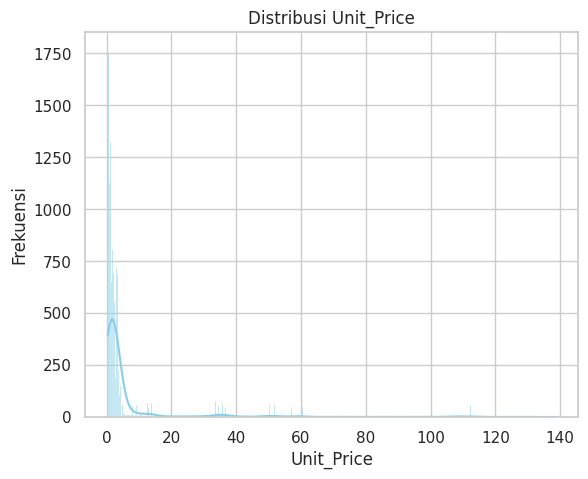

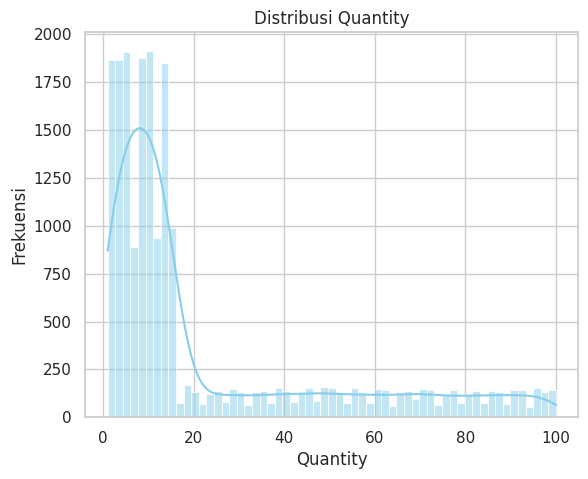

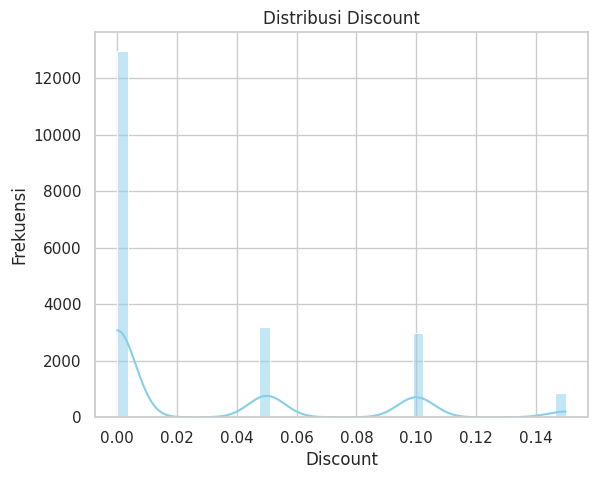

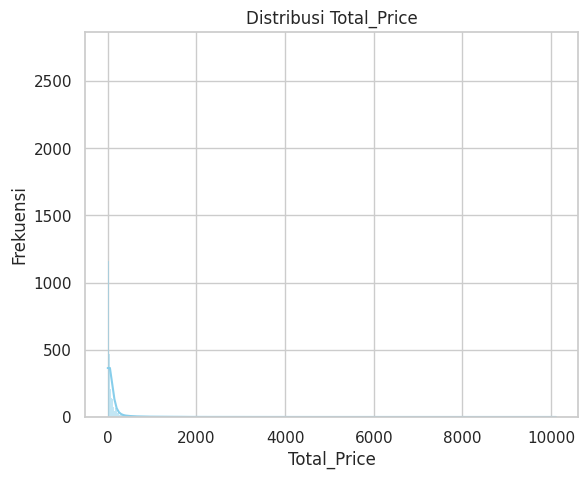

In [54]:
print("\nStatistik Deskriptif Kolom Numerikal:")
print(df_sample[numeric_columns].describe())



# Visualisasi histogram dan boxplot untuk setiap kolom numerikal
for col in numeric_columns:
    plt.figure(figsize=(14, 5))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(df_sample[col], kde=True, color='skyblue')
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')

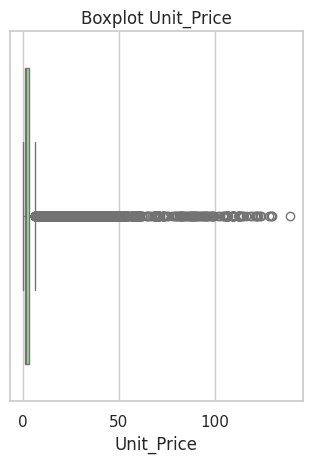

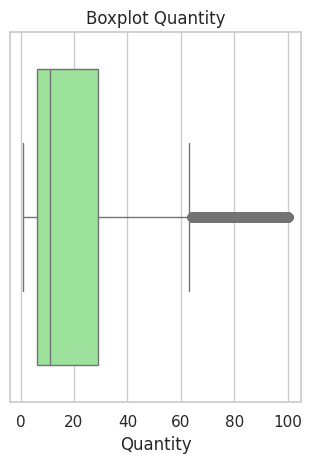

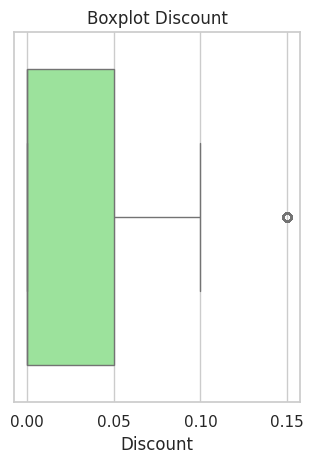

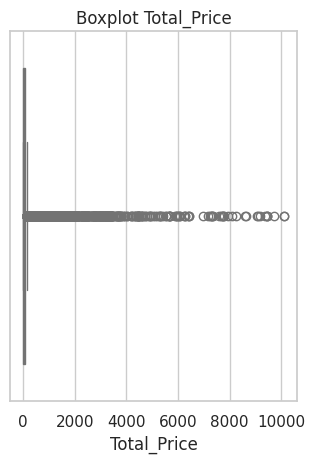

In [55]:
# Boxplot untuk melihat outlier pada kolom 'Quantity'
for col in numeric_columns:
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df_sample[col], color='lightgreen')
    plt.title(f'Boxplot {col}')
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

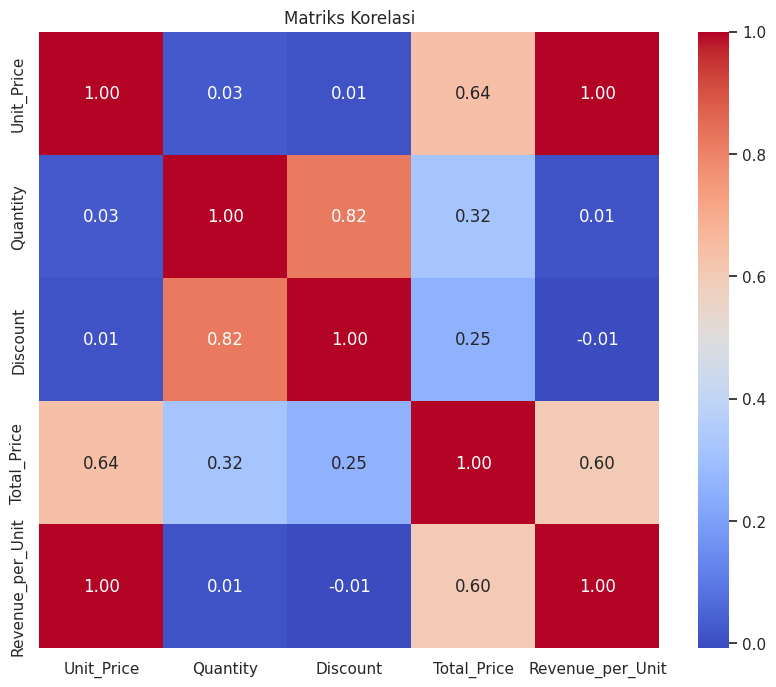

In [56]:
# Memilih hanya kolom dengan tipe data numerik
numeric_df = df_sample.select_dtypes(include=['float64', 'int64'])

# Menghitung korelasi pada kolom numerik
corr_matrix = numeric_df.corr()

# Visualisasi matriks korelasi menggunakan heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi')
plt.show()


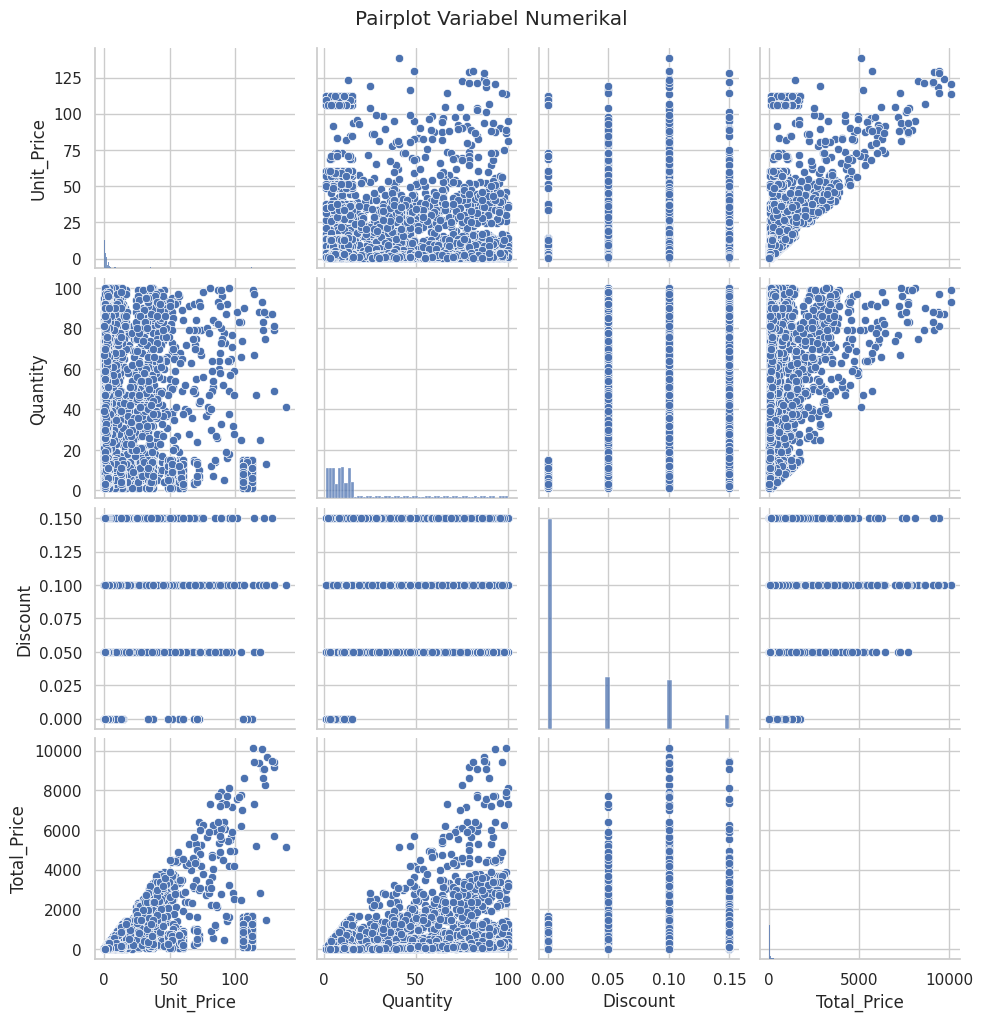

In [57]:
# Visualisasi korelasi dengan pairplot untuk kolom numerikal
sns.pairplot(df_sample[numeric_columns])
plt.suptitle('Pairplot Variabel Numerikal', y=1.02)
plt.show()

<ipython-input-58-305f5439f973>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df_sample, palette='pastel')


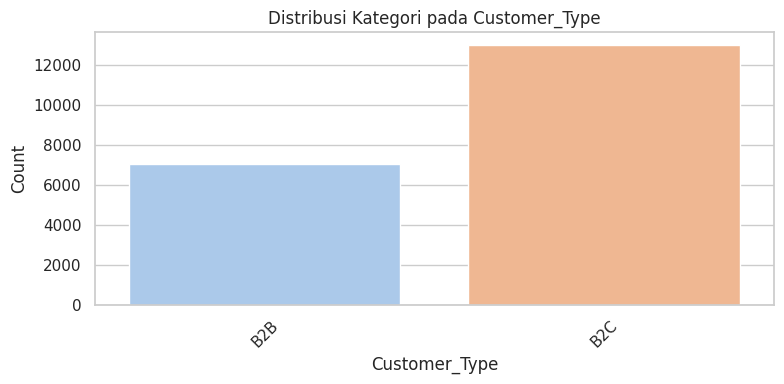

<ipython-input-58-305f5439f973>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df_sample, palette='pastel')


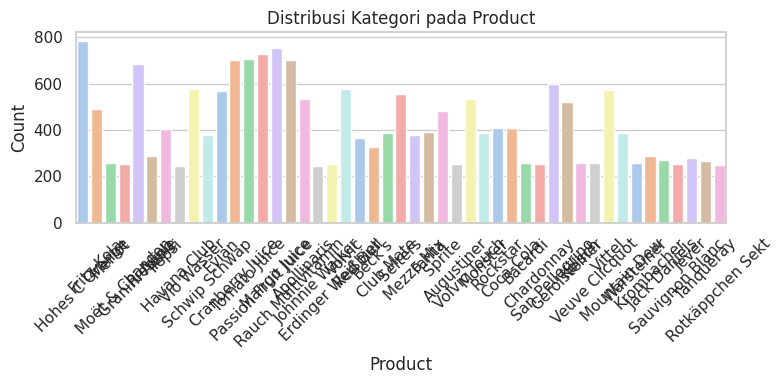

<ipython-input-58-305f5439f973>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df_sample, palette='pastel')


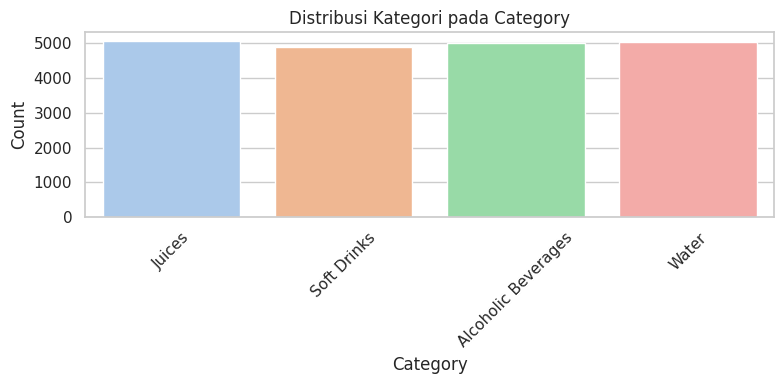

<ipython-input-58-305f5439f973>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df_sample, palette='pastel')


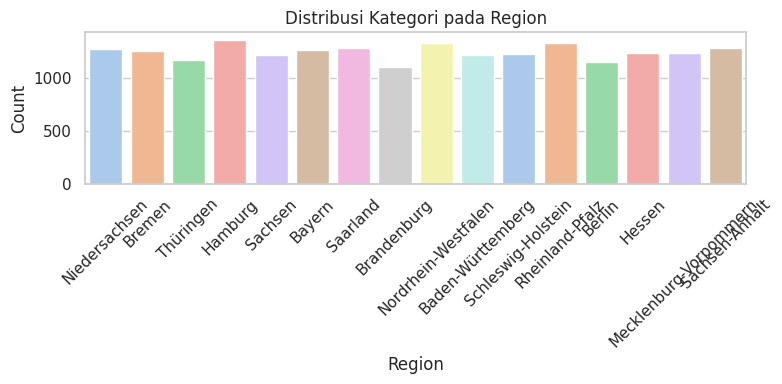

In [58]:
# Untuk setiap kolom kategorikal, tampilkan countplot
# Buat salinan DataFrame tanpa kolom ID
df_dist = df_sample.drop(columns=['Order_ID', 'Customer_ID'])

categorical_columns = df_dist.select_dtypes(include=['object', 'category']).columns

for col in categorical_columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=col, data=df_sample, palette='pastel')
    plt.title(f'Distribusi Kategori pada {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

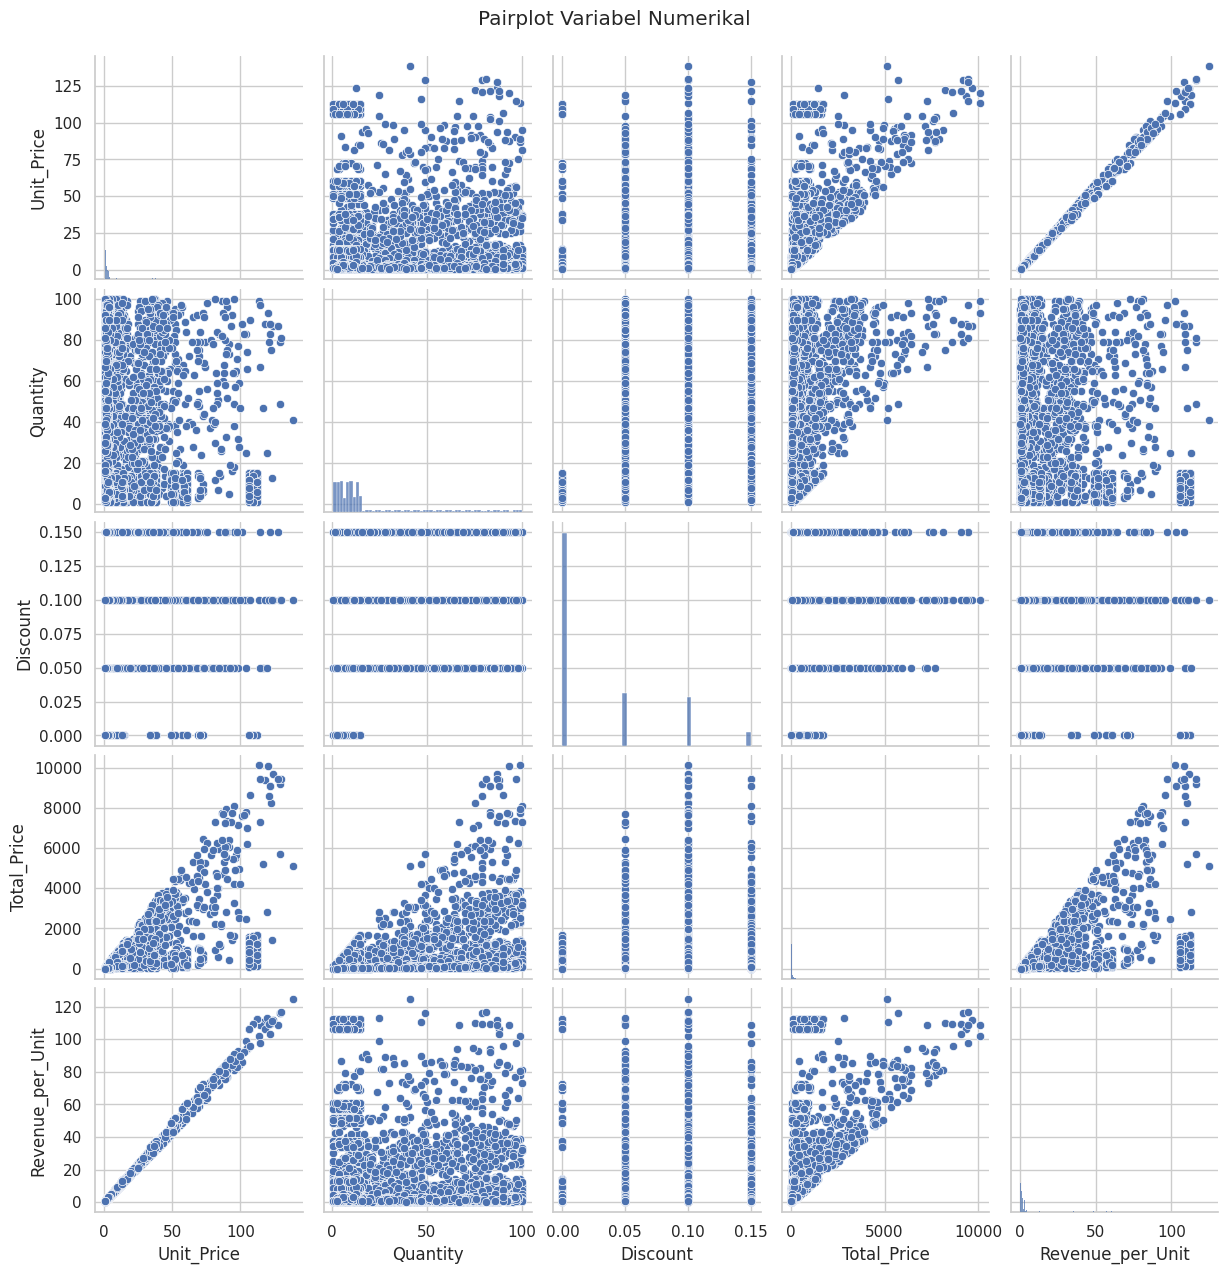

In [59]:
sns.pairplot(df_sample.select_dtypes(include=['float64', 'int64']))
plt.suptitle('Pairplot Variabel Numerikal', y=1.02)
plt.show()


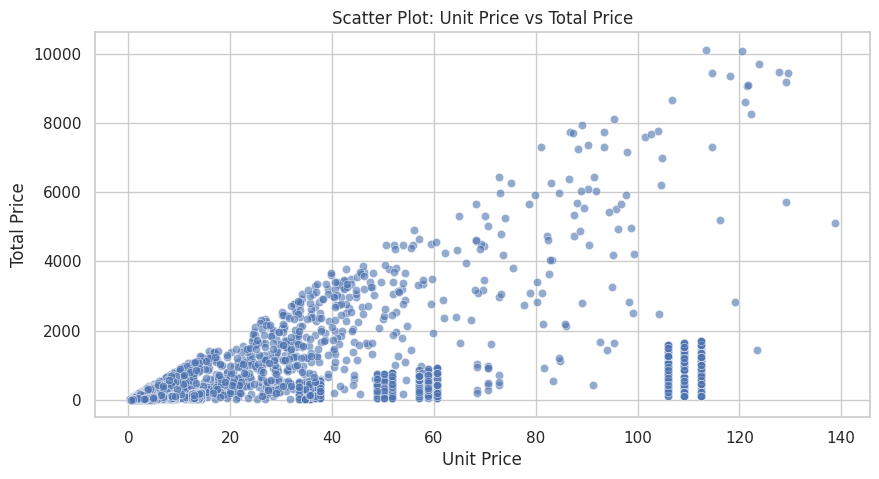

In [60]:
# Scatter Plot Antar Beberapa Variabel Numerikal
# Jika ingin melihat hubungan antara pasangan variabel numerikal tertentu,
if 'Unit_Price' in numeric_columns and 'Total_Price' in numeric_columns:
    plt.figure(figsize=(10, 5))
    sns.scatterplot(x='Unit_Price', y='Total_Price', data=df_sample, alpha=0.6)
    plt.title('Scatter Plot: Unit Price vs Total Price')
    plt.xlabel('Unit Price')
    plt.ylabel('Total Price')
    plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning. Data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah.

In [61]:
# Menghapus Data Duplikat
df_sample.drop_duplicates(inplace=True)
print("Jumlah baris setelah menghapus duplikat:", df_sample.shape[0])

# Menghapus kolom ID dari dataset
df_sample = df_sample.drop(['Order_ID', 'Customer_ID'], axis=1)

Jumlah baris setelah menghapus duplikat: 20000


In [62]:
df_sample.head()

,Customer_Type,Product,Category,Unit_Price,Quantity,Discount,Total_Price,Region,Order_Date,Order_Month,Revenue_per_Unit,Customer_Type_Encoded,Category_Encoded,Unit_Price_Bin,cluster,cluster_pca
4990465,0,15,1,1.87,74,0.10,124.54,8,2023-11-29,11,1.682973,0,1,1,0,0
5995542,0,11,2,1.87,18,0.05,31.98,4,2021-05-13,5,1.776667,0,2,1,0,0
1044351,0,22,0,12.04,71,0.15,726.61,15,2021-04-21,4,10.233944,0,0,1,0,0
1802181,0,26,0,64.91,91,0.10,5316.13,5,2021-08-23,8,58.419011,0,0,2,2,1
6900691,1,13,1,1.64,4,0.00,6.56,12,2022-10-16,10,1.640000,1,1,1,0,0


In [63]:
# Normalisasi atau Standarisasi Fitur Numerikal
numeric_cols = df_sample.select_dtypes(include=['int64', 'float64']).columns
scaler = StandardScaler()



In [64]:
# # Deteksi dan Penanganan Outlier
# def remove_outliers(df, col):
#     Q1 = df[col].quantile(0.25)
#     Q3 = df[col].quantile(0.75)
#     IQR = Q3 - Q1
#     lower_bound = Q1 - 1.5 * IQR
#     upper_bound = Q3 + 1.5 * IQR
#     # Menyimpan data tanpa outlier
#     df_filtered = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
#     return df_filtered

# if 'Total_Price' in numeric_cols:
#     df_sample = remove_outliers(df_sample, 'Total_Price')
#     print("Ukuran dataset setelah penghapusan outlier pada Total_Price:", df_sample.shape)

In [65]:
#  Encoding Data Kategorikal
# Gunakan LabelEncoder untuk mengubah data kategorikal menjadi numerik
categorical_cols = df_sample.select_dtypes(include=['object', 'category']).columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_sample[col] = le.fit_transform(df_sample[col])
    label_encoders[col] = le  # Simpan encoder jika diperlukan untuk inverse transformasi di masa depan


In [66]:
# Lakukan encoding pada fitur kategorikal
le_customer = LabelEncoder()
df_sample['Customer_Type_Encoded'] = le_customer.fit_transform(df_sample['Customer_Type'])

# Definisikan X dengan 5 fitur: 4 numerikal dan 1 kategorikal hasil encoding
selected_features = numeric_features + ['Customer_Type_Encoded']
X = df_sample[selected_features].copy()


# Lakukan encoding pada kolom 'Category'
le_cat = LabelEncoder()
df_sample['Category_Encoded'] = le_cat.fit_transform(df_sample['Category'])

# Simpan encoder dalam dictionary (untuk digunakan di inverse transform)

label_encoders = {'Category': le_cat}
print("Jumlah fitur yang digunakan:", X.shape[1])
print("Fitur yang digunakan:", X.columns.tolist())

Jumlah fitur yang digunakan: 5
Fitur yang digunakan: ['Unit_Price', 'Quantity', 'Total_Price', 'Revenue_per_Unit', 'Customer_Type_Encoded']


In [67]:
# Binning (Pengelompokan Data)
# Contoh: Melakukan binning pada kolom numerikal 'Unit_Price' menjadi 3 kategori (Low, Medium, High)
if 'Unit_Price' in df_sample.columns:
    df_sample['Unit_Price_Bin'] = pd.cut(df_sample['Unit_Price'], bins=3, labels=['Low', 'Medium', 'High'])
    # Jika ingin melakukan encoding setelah binning:
    df_sample['Unit_Price_Bin'] = LabelEncoder().fit_transform(df_sample['Unit_Price_Bin'])

# Setelah semua preprocessing, periksa kembali data
print("\nInformasi dataset setelah preprocessing:")
print(df_sample.info())
print("\nStatistik deskriptif dataset setelah preprocessing:")
print(df_sample.describe())



Informasi dataset setelah preprocessing:
<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 4990465 to 653003
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Customer_Type          20000 non-null  int64         
 1   Product                20000 non-null  int64         
 2   Category               20000 non-null  int64         
 3   Unit_Price             20000 non-null  float64       
 4   Quantity               20000 non-null  int64         
 5   Discount               20000 non-null  float64       
 6   Total_Price            20000 non-null  float64       
 7   Region                 20000 non-null  int64         
 8   Order_Date             20000 non-null  datetime64[ns]
 9   Order_Month            20000 non-null  int32         
 10  Revenue_per_Unit       20000 non-null  float64       
 11  Customer_Type_Encoded  20000 non-null  int64         
 12  Category_Encoded

In [68]:
min_price = df_sample['Unit_Price'].min()
max_price = df_sample['Unit_Price'].max()

bins = np.linspace(min_price, max_price, 4)
df_sample['Unit_Price_Bin'] = pd.cut(df_sample['Unit_Price'], bins=bins, labels=['Low', 'Medium', 'High'])
df_sample['Unit_Price_Bin'] = LabelEncoder().fit_transform(df_sample['Unit_Price_Bin'])



# **6. Pembangunan Model Clustering**

## **a. Pembangunan Model Clustering**

Pada tahap ini, Anda membangun model clustering dengan memilih algoritma yang sesuai untuk mengelompokkan data berdasarkan kesamaan. Berikut adalah **rekomendasi** tahapannya.
1. Pilih algoritma clustering yang sesuai.
2. Latih model dengan data menggunakan algoritma tersebut.

In [69]:
# Pilih jumlah cluster awal (contoh: 3)
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(X)

# Menyimpan label cluster ke dalam dataframe
df_sample['cluster'] = kmeans.labels_

print("Label cluster unik:", df_sample['cluster'].unique())


Label cluster unik: [0 2 1]


## **b. Evaluasi Model Clustering**

Untuk menentukan jumlah cluster yang optimal dalam model clustering, Anda dapat menggunakan metode Elbow atau Silhouette Score.

Metode ini membantu kita menemukan jumlah cluster yang memberikan pemisahan terbaik antar kelompok data, sehingga model yang dibangun dapat lebih efektif. Berikut adalah **rekomendasi** tahapannya.
1. Gunakan Silhouette Score dan Elbow Method untuk menentukan jumlah cluster optimal.
2. Hitung Silhouette Score sebagai ukuran kualitas cluster.

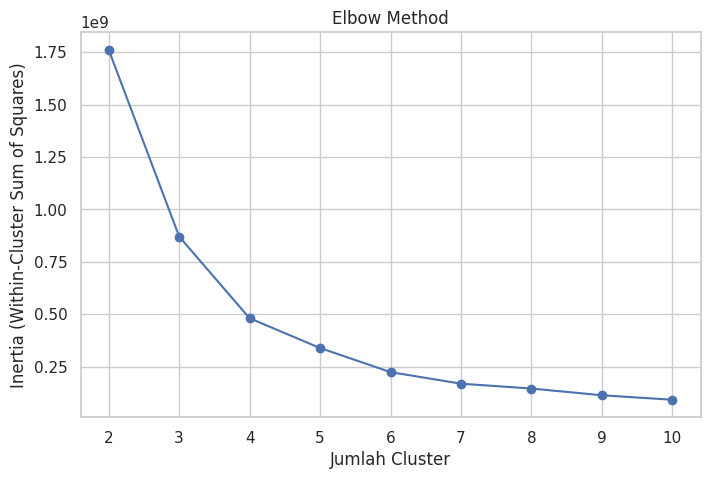

In [70]:
# Mencari inertia untuk berbagai nilai cluster
inertia = []
cluster_range = range(2, 11)
for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(cluster_range, inertia, marker='o')
plt.xlabel('Jumlah Cluster')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Elbow Method')
plt.show()


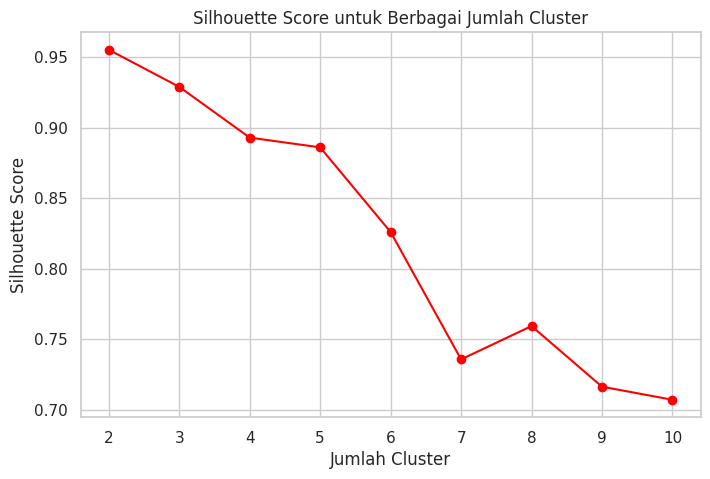

Jumlah cluster optimal berdasarkan Silhouette Score: 2


In [71]:
#menggunakan silhouette

silhouette_scores = []
for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(X)
    score = silhouette_score(X, cluster_labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(cluster_range, silhouette_scores, marker='o', color='red')
plt.xlabel('Jumlah Cluster')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score untuk Berbagai Jumlah Cluster')
plt.show()

# Cetak nilai terbaik (jumlah cluster dengan skor tertinggi)
optimal_k = cluster_range[silhouette_scores.index(max(silhouette_scores))]
print("Jumlah cluster optimal berdasarkan Silhouette Score:", optimal_k)


## **c. Feature Selection (Opsional)**

Silakan lakukan feature selection jika Anda membutuhkan optimasi model clustering. Jika Anda menerapkan proses ini, silakan lakukan pemodelan dan evaluasi kembali menggunakan kolom-kolom hasil feature selection. Terakhir, bandingkan hasil performa model sebelum dan sesudah menerapkan feature selection.

In [72]:
# Ubah PCA untuk feature selection agar menghasilkan 2 komponen
pca_feature = PCA(n_components=2, random_state=42)
X_pca = pca_feature.fit_transform(X)

print("Jumlah fitur asli:", X.shape[1])
print("Jumlah fitur setelah PCA (feature selection):", X_pca.shape[1])

# Lakukan clustering pada data hasil PCA dengan jumlah cluster optimal
kmeans_pca = KMeans(n_clusters=optimal_k, random_state=42)
kmeans_pca.fit(X_pca)
df_sample['cluster_pca'] = kmeans_pca.labels_

# Evaluasi menggunakan Silhouette Score
score_pca = silhouette_score(X_pca, kmeans_pca.labels_)
print("Silhouette Score dengan PCA:", score_pca)

Jumlah fitur asli: 5
Jumlah fitur setelah PCA (feature selection): 2
Silhouette Score dengan PCA: 0.955615260296815


In [73]:
print("Hasil score silhouette sebelum PCA")

# Mengiterasi jumlah cluster dari 2 hingga 10 untuk data asli (sebelum PCA)
cluster_range = list(range(2, 11))
silhouette_scores = []
for k in cluster_range:
    kmeans_orig = KMeans(n_clusters=k, random_state=42)
    kmeans_orig.fit(X)
    score_orig = silhouette_score(X, kmeans_orig.labels_)
    silhouette_scores.append(score_orig)
    print(f"Jumlah Cluster = {k}, Silhouette Score sebelum PCA : {score_orig:.4f}")

print("Hasil score silhouette setelah PCA")

# Terapkan PCA untuk mereduksi dimensi ke 2 komponen untuk keperluan visualisasi dan evaluasi.
pca_feature = PCA(n_components=2, random_state=42)
X_pca = pca_feature.fit_transform(X)

silhouette_pca = []
# Mengiterasi jumlah cluster dari 2 hingga 10 untuk data hasil PCA
for k in cluster_range:
    kmeans_pca = KMeans(n_clusters=k, random_state=42)
    kmeans_pca.fit(X_pca)
    score_pca = silhouette_score(X_pca, kmeans_pca.labels_)
    silhouette_pca.append(score_pca)
    print(f"Jumlah Cluster = {k}, Silhouette Score setelah PCA : {score_pca:.4f}")

Hasil score silhouette sebelum PCA
Jumlah Cluster = 2, Silhouette Score sebelum PCA : 0.9554
Jumlah Cluster = 3, Silhouette Score sebelum PCA : 0.9290
Jumlah Cluster = 4, Silhouette Score sebelum PCA : 0.8930
Jumlah Cluster = 5, Silhouette Score sebelum PCA : 0.8861
Jumlah Cluster = 6, Silhouette Score sebelum PCA : 0.8260
Jumlah Cluster = 7, Silhouette Score sebelum PCA : 0.7357
Jumlah Cluster = 8, Silhouette Score sebelum PCA : 0.7593
Jumlah Cluster = 9, Silhouette Score sebelum PCA : 0.7163
Jumlah Cluster = 10, Silhouette Score sebelum PCA : 0.7070
Hasil score silhouette setelah PCA
Jumlah Cluster = 2, Silhouette Score setelah PCA : 0.9556
Jumlah Cluster = 3, Silhouette Score setelah PCA : 0.9296
Jumlah Cluster = 4, Silhouette Score setelah PCA : 0.8953
Jumlah Cluster = 5, Silhouette Score setelah PCA : 0.8887
Jumlah Cluster = 6, Silhouette Score setelah PCA : 0.8153
Jumlah Cluster = 7, Silhouette Score setelah PCA : 0.7490
Jumlah Cluster = 8, Silhouette Score setelah PCA : 0.7199
J

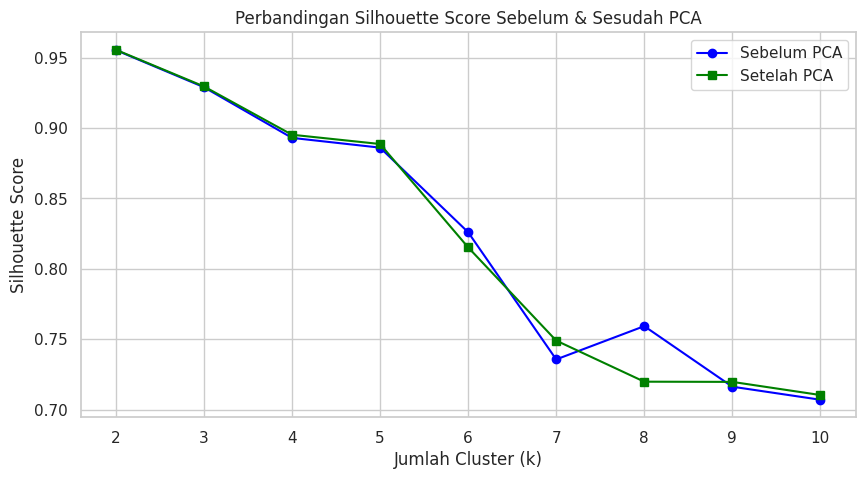

In [74]:
plt.figure(figsize=(10, 5))
plt.plot(cluster_range, silhouette_scores, marker='o', linestyle='-', label="Sebelum PCA", color="blue")
plt.plot(cluster_range, silhouette_pca, marker='s', linestyle='-', label="Setelah PCA", color="green")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Perbandingan Silhouette Score Sebelum & Sesudah PCA")
plt.xticks(cluster_range)
plt.legend()
plt.grid(True)
plt.show()


## **d. Visualisasi Hasil Clustering**

Setelah model clustering dilatih dan jumlah cluster optimal ditentukan, langkah selanjutnya adalah menampilkan hasil clustering melalui visualisasi.

Berikut adalah **rekomendasi** tahapannya.
1. Tampilkan hasil clustering dalam bentuk visualisasi, seperti grafik scatter plot atau 2D PCA projection.

Bentuk X: (20000, 5)


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


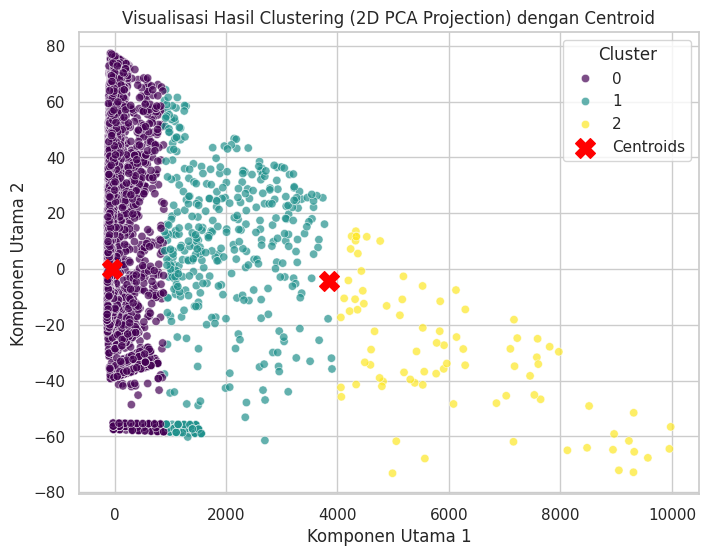

In [75]:

# Misalnya, X adalah data asli dengan 5 fitur (contoh: sudah distandarisasi)
# Pastikan X memiliki 5 fitur
print("Bentuk X:", X.shape)

# Latih model kmeans pada data asli X
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans.fit(X)
centroids = kmeans.cluster_centers_  # Bentuk: (n_clusters, 5)

# Fit PCA untuk visualisasi ke 2 dimensi
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X)

# Proyeksikan centroid ke ruang 2D
centroids_2d = pca_2d.transform(centroids)

# Plot hasil clustering dengan centroid
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df_sample['cluster'], palette='viridis', alpha=0.7)
plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='X', s=200, c='red', label='Centroids')
plt.title('Visualisasi Hasil Clustering (2D PCA Projection) dengan Centroid')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.legend(title='Cluster')
plt.show()

## **e. Analisis dan Interpretasi Hasil Cluster**

### Interpretasi Target

**Tutorial: Melakukan Inverse Transform pada Data Target Setelah Clustering**

Setelah melakukan clustering dengan model **KMeans**, kita perlu mengembalikan data yang telah diubah (normalisasi, standarisasi, atau label encoding) ke bentuk aslinya. Berikut adalah langkah-langkahnya.

---

**1. Tambahkan Hasil Label Cluster ke DataFrame**
Setelah mendapatkan hasil clustering, kita tambahkan label cluster ke dalam DataFrame yang telah dinormalisasi.

```python
df_normalized['Cluster'] = model_kmeans.labels_
```

Lakukan Inverse Transform pada feature yang sudah dilakukan Labelisasi dan Standararisasi. Berikut code untuk melakukannya:
label_encoder.inverse_transform(X_Selected[['Fitur']])

Lalu masukkan ke dalam kolom dataset asli atau membuat dataframe baru
```python
df_normalized['Fitur'] = label_encoder.inverse_transform(df_normalized[['Fitur']])
```
Masukkan Data yang Sudah Di-Inverse ke dalam Dataset Asli atau Buat DataFrame Baru
```python
df_original['Fitur'] = df_normalized['Fitur']
```

In [76]:
numeric_cols = ['Unit_Price', 'Quantity', 'Total_Price', 'Revenue_per_Unit']

model_kmeans = KMeans(n_clusters=3, random_state=42)
model_kmeans.fit(X)
# Buat DataFrame untuk data yang telah dinormalisasi (copy dari X)
df_normalized = X.copy()
# Tambahkan label cluster ke df_normalized
df_normalized['Cluster'] = model_kmeans.labels_

### Inverse Data Jika Melakukan Normalisasi/Standardisasi

Inverse Transform untuk Data yang Distandarisasi
Jika data numerik telah dinormalisasi menggunakan StandardScaler atau MinMaxScaler, kita bisa mengembalikannya ke skala asli:
```python
df_normalized[['Fitur_Numerik']] = scaler.inverse_transform(df_normalized[['Fitur_Numerik']])
```

In [77]:
# Buat df_normalized sebagai salinan dari df_sample (pastikan semua kolom sudah ada)
df_normalized = df_sample.copy()
print("Kolom di df_normalized:", df_normalized.columns.tolist())

# Inverse Transform Data Numerikal
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(df_normalized[numeric_cols])
df_normalized[numeric_cols] = scaler.inverse_transform(df_normalized[numeric_cols])
print("Inverse transform numerikal selesai.")

# Inverse Transform Data Kategorikal
# Gunakan kolom 'Category_Encoded' untuk inverse transform
label_encoder = label_encoders['Category']
df_normalized['Category_Original'] = label_encoder.inverse_transform(df_sample['Category_Encoded'].values.ravel())
print("Inverse transform kategorikal selesai.")

# Gabungkan Hasil Inverse Transform ke Data Asli
df_original = df_sample.copy()
df_original['Unit_Price'] = df_normalized['Unit_Price']
df_original['Quantity'] = df_normalized['Quantity']
df_original['Total_Price'] = df_normalized['Total_Price']
df_original['Revenue_per_Unit'] = df_normalized['Revenue_per_Unit']
df_original['Category'] = df_normalized['Category_Original']
df_original['Cluster'] = df_normalized['cluster']


Kolom di df_normalized: ['Customer_Type', 'Product', 'Category', 'Unit_Price', 'Quantity', 'Discount', 'Total_Price', 'Region', 'Order_Date', 'Order_Month', 'Revenue_per_Unit', 'Customer_Type_Encoded', 'Category_Encoded', 'Unit_Price_Bin', 'cluster', 'cluster_pca']
Inverse transform numerikal selesai.
Inverse transform kategorikal selesai.


Setelah melakukan clustering, langkah selanjutnya adalah menganalisis karakteristik dari masing-masing cluster berdasarkan fitur yang tersedia.

Berikut adalah **rekomendasi** tahapannya.
1. Analisis karakteristik tiap cluster berdasarkan fitur yang tersedia (misalnya, distribusi nilai dalam cluster).
2. Berikan interpretasi: Apakah hasil clustering sesuai dengan ekspektasi dan logika bisnis? Apakah ada pola tertentu yang bisa dimanfaatkan?

In [78]:
# Analisis Karakteristik Tiap Cluster
# Kelompokkan data berdasarkan 'Cluster' dan hitung rata-rata tiap fitur numerikal
cluster_means = df_original.groupby('Cluster')[numeric_cols].mean()
print("Rata-rata tiap fitur per cluster:")
print(cluster_means)


Rata-rata tiap fitur per cluster:
          Unit_Price     Quantity   Total_Price  Revenue_per_Unit
Cluster                                                          
0          73.162343   604.972368  3.478267e+04         70.025030
1         761.620637  1525.815234  1.043172e+06        699.402564
2        1338.172887  2126.498029  3.272716e+06       1168.892985


<ipython-input-79-60fbb4ec1b04>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='Unit_Price', data=df_original, palette='Set3')


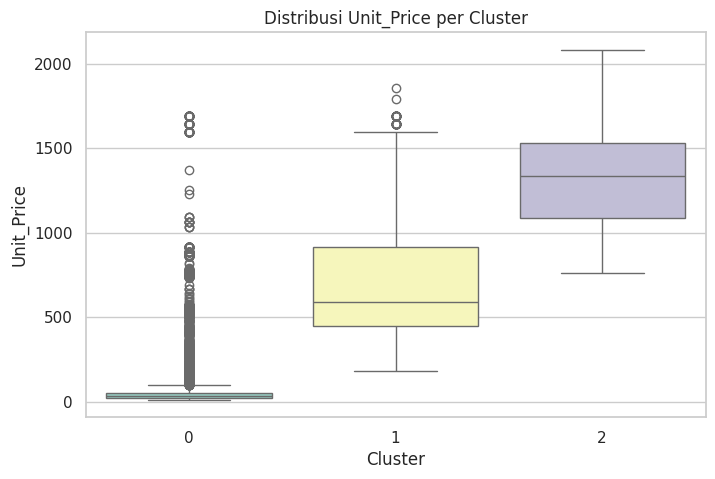

In [79]:
# Visualisasi distribusi fitur per cluster
plt.figure(figsize=(8, 5))
sns.boxplot(x='Cluster', y='Unit_Price', data=df_original, palette='Set3')
plt.title('Distribusi Unit_Price per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Unit_Price')
plt.show()

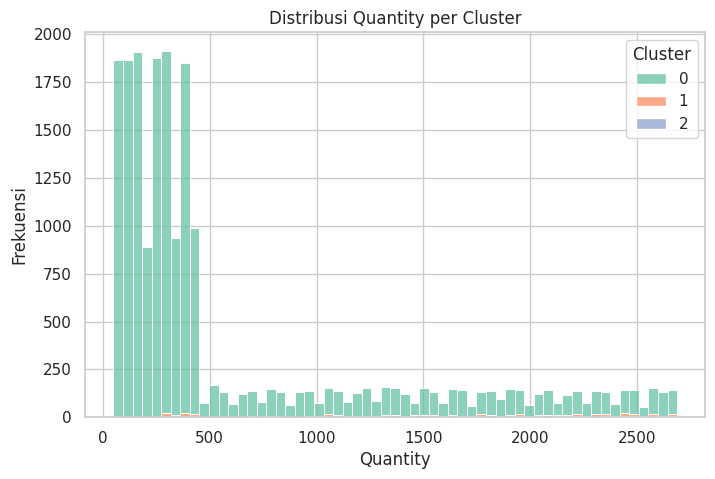

In [80]:
# Contoh visualisasi lain: Histogram untuk 'Quantity'
plt.figure(figsize=(8, 5))
sns.histplot(data=df_original, x='Quantity', hue='Cluster', multiple='stack', palette='Set2')
plt.title('Distribusi Quantity per Cluster')
plt.xlabel('Quantity')
plt.ylabel('Frekuensi')
plt.show()

In [81]:
# Menghitung agregasi untuk fitur numerikal per cluster
cluster_agg = df_original.groupby('Cluster').agg({
    'Unit_Price': ['min', 'mean', 'max'],
    'Quantity': ['min', 'mean', 'max'],
    'Total_Price': ['min', 'mean', 'max'],
    'Revenue_per_Unit': ['min', 'mean', 'max']
})
print("Agregasi tiap fitur per cluster:")
print(cluster_agg)

# Menghitung modus untuk fitur kategorikal, misalnya 'Customer_Type'
cluster_mode = df_original.groupby('Cluster')['Customer_Type'].agg(lambda x: x.mode()[0])
print("\nModus Customer_Type per cluster:")
print(cluster_mode)


Agregasi tiap fitur per cluster:
         Unit_Price                               Quantity               \
                min         mean          max          min         mean   
Cluster                                                                   
0         10.808885    73.162343  1689.441115    49.498189   604.972368   
1        180.423646   761.620637  1853.666528   289.335043  1525.815234   
2        763.521170  1338.172887  2082.564118  1115.439760  2126.498029   

                       Total_Price                              \
                 max           min          mean           max   
Cluster                                                          
0        2687.703576  3.183778e+02  3.478267e+04  5.386544e+05   
1        2687.703576  5.417843e+05  1.043172e+06  2.125714e+06   
2        2687.703576  2.209643e+06  3.272716e+06  5.328357e+06   

        Revenue_per_Unit                            
                     min         mean          max  
Cluster      

Tulis hasil interpretasinya di sini.
1. Cluster 0 Pelanggan B2C dengan Pembelian Volume Sedang-Harga Menengah

2. Cluster 1 Pelanggan B2B dengan Pembelian Grosir Harga Premium

3. Cluster 2 Pelanggan B2B dengan Pembelian High-End Skala Besar

#Analisis Karakteristik Cluster
#Cluster 0: Pelanggan B2C dengan Pembelian Volume Sedang-Harga Menengah
- Unit_Price:

  - Rata-rata: 73.16 (min: 10.81, max: 1,689.44)

  - Harga per unit bervariasi dari menengah hingga tinggi, tetapi dominan di kisaran menengah (rata-rata <100).

- Quantity:

  - Rata-rata: 604.97 (min: 49.50, max: 2,687.70)

  - Pembelian dalam jumlah cukup besar, tetapi tidak ekstrem.

- Total_Price:

  - Rata-rata: 34,782.67 (min: 318.38, max: 538,654.40)

  - Nilai transaksi tinggi karena kombinasi harga dan kuantitas.

- Revenue_per_Unit:

  - Rata-rata: 70.03 (min: 10.01, max: 1,644.33)

  - Margin revenue per unit cukup kompetitif.

- Customer_Type:

  - Modus: 1 (B2C)

Interpretasi:
Pelanggan B2C yang melakukan pembelian produk dengan harga sedang dalam jumlah besar (misal: restoran atau toko ritel menengah). Total transaksi tinggi karena kuantitas, tetapi harga per unit belum mencapai kategori premium.

#Cluster 1: Pelanggan B2B dengan Pembelian Grosir Harga Premium
- Unit_Price:

  - Rata-rata: 761.62 (min: 180.42, max: 1,853.67)

  - Harga per unit sangat tinggi, masuk kategori produk premium.

- Quantity:

  - Rata-rata: 1,525.82 (min: 289.34, max: 2,687.70)

  - Pembelian dalam jumlah sangat besar, menunjukkan pola grosir.

- Total_Price:

  - Rata-rata: 1,043,172 (min: 541,784.3, max: 2,125,714)

  - Nilai transaksi tertinggi kedua, didorong harga premium dan kuantitas tinggi.

- Revenue_per_Unit:

  - Rata-rata: 699.40 (min: 158.60, max: 1,654.45)

  - Margin revenue sangat tinggi, mengindikasikan produk bernilai tambah.

- Customer_Type:

  - Modus: 0 (B2B)

Interpretasi:
Pelanggan B2B yang membeli produk premium dalam skala grosir (misal: distributor barang mewah atau perusahaan manufaktur). Pola pembelian stabil dengan margin menguntungkan.

#Cluster 2: Pelanggan B2B dengan Pembelian High-End Skala Besar
- Unit_Price:

  - Rata-rata: 1,338.17 (min: 763.52, max: 2,082.56)

  - Harga per unit tertinggi, kategori produk eksklusif/niche.

- Quantity:

  - Rata-rata: 2,126.50 (min: 1,115.44, max: 2,687.70)

  - Pembelian dalam jumlah terbesar, mendekati kapasitas maksimal.

- Total_Price:

  - Rata-rata: 3,272,716 (min: 2,209,643, max: 5,328,357)

  - Nilai transaksi tertinggi, dominan dari segmen korporasi besar.

- Revenue_per_Unit:

  - Rata-rata: 1,168.89 (min: 690.23, max: 1,824.83)

  - Margin tertinggi, menunjukkan produk bernilai strategis.

- Customer_Type:

  - Modus: 0 (B2B)

Interpretasi:
Pelanggan korporasi besar (misal: perusahaan multinasional atau institusi pemerintah) yang membeli produk high-end untuk kebutuhan strategis. Pembelian bersifat kontrak jangka panjang.

#Rekomendasi Bisnis
- Cluster 0 (B2C Volume Menengah):

  - Tingkatkan loyalitas dengan program diskon volume.

  - Prioritaskan pengiriman cepat untuk mempertahankan kepuasan.

- Cluster 1 (B2B Grosir Premium):

  - Tawarkan paket bundling dengan layanan purna jual (maintenance, garansi ekstra).

  - Bangun hubungan jangka panjang dengan negosiasi kontrak tahunan.

- Cluster 2 (B2B High-End):

  - Siapkan tim khusus untuk layanan 24/7.

  - Kembangkan produk custom sesuai kebutuhan spesifik pelanggan.

# **7. Mengeksport Data**

Simpan hasilnya ke dalam file CSV.

In [82]:
# Simpan DataFrame df_original ke dalam file CSV tanpa menyertakan indeks
df_original.to_csv("hasil_clustering.csv", index=False)
print("Data hasil clustering telah berhasil disimpan ke file 'hasil_clustering.csv'")


Data hasil clustering telah berhasil disimpan ke file 'hasil_clustering.csv'
